# Análisis exploratorio: Airbnb Bogotá

Este análisis consulta MongoDB (no lee los CSV directamente) y documenta estructura, calidad y distribuciones antes de transformar. Ejecuta las celdas en orden después de configurar `.env` según `README.md`.

**Fuente:** colecciones `Listings`, `Reviews` y `Calendar` de la base local MongoDB. Los resultados y conclusiones se calculan sobre los datos disponibles en esa base.

In [1]:
from pathlib import Path
import sys
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

project_root = Path.cwd()
if not (project_root / "src").exists():
    project_root = project_root.parent
sys.path.insert(0, str(project_root))

from src.extraccion import Extraccion

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 80)
data = Extraccion().extraer()
list(data)

2026-10-11 11:06:17 | INFO | Archivo de log: C:\Users\Robin Montoya\OneDrive - INSTITUTO TECNOLOGICO METROPOLITANO - ITM\Documents\TallerETL2\TallerETL\logs\log_20261011_110617.log
2026-10-11 11:06:17 | INFO | Conexión a MongoDB exitosa; base de datos: bogota
2026-10-11 11:06:19 | INFO | Colección Listings extraída: 19187 registros
2026-10-11 11:06:24 | INFO | Colección Reviews extraída: 527731 registros
2026-10-11 11:07:22 | INFO | Colección Calendar extraída: 7003255 registros


['Listings', 'Reviews', 'Calendar']

## 1. Entendimiento general y calidad

Se muestran muestras, dimensiones, tipos, resúmenes descriptivos, nulos y duplicados exactos por colección. Los nulos parciales se reportan para orientar transformaciones, no se eliminan automáticamente en bloque.

In [2]:
def count_duplicates(frame):
    """Cuenta duplicados exactos ignorando el identificador técnico de MongoDB."""
    import json

    comparable = frame.drop(columns=["_id"], errors="ignore").copy()
    unhashable = [
        column for column in comparable.columns
        if comparable[column].map(lambda value: isinstance(value, (list, dict, set))).any()
    ]
    for column in unhashable:
        comparable[column] = comparable[column].map(
            lambda value: json.dumps(value, ensure_ascii=False, sort_keys=True, default=str)
            if isinstance(value, (list, dict, tuple))
            else json.dumps(sorted(value, key=str), ensure_ascii=False, default=str)
            if isinstance(value, set)
            else value
        )
    return int(comparable.duplicated().sum()), unhashable

In [3]:
quality = {}
for name, frame in data.items():
    print(f"\n{'=' * 80}\n{name}: primeras filas")
    display(frame.head())
    print(f"Dimensiones: {frame.shape[0]:,} filas x {frame.shape[1]:,} columnas")
    frame.info()
    print("Resumen de variables numéricas:")
    display(frame.describe(include="number").T)

    nulls = frame.isna().sum().sort_values(ascending=False)
    nulls = nulls[nulls > 0]

    duplicates, unhashable_cols = count_duplicates(frame)
    quality[name] = {"rows": len(frame), "columns": len(frame.columns),
                     "duplicates": duplicates, "nulls": nulls}

    print(f"Duplicados exactos: {duplicates:,}")
    if unhashable_cols:
        print(f"Columnas con listas/dicts (convertidas a texto para comparar): {unhashable_cols}")
    print("Nulos por columna (solo columnas con nulos):")
    display(nulls.to_frame("missing_count"))
    print("Variables relevantes disponibles:",
          [c for c in frame.columns if c in {
              "price", "minimum_nights", "availability_365", "date",
              "review_scores_rating", "neighbourhood_cleansed", "room_type"
          }])


Listings: primeras filas


,_id,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,...,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,6ac947838e4f4a5224ce1fb0,27841,https://www.airbnb.com/rooms/27841,20260621155658,2026-06-22,city scrape,Rosales Luxury Large 2BR Boutique Apt,Amazing bright 135m2 (1350 sq ft) apartment l...,None,https://a0.muscache.com/pictures/38377482/1df3...,113734,https://www.airbnb.com/users/show/113734,1462509905126026119,https://www.airbnb.com/users/profile/146250990...,Marcela,None,16,1,15,5,"Bogota, Colombia","I am an Architect and Urban Planner ,with my o...",None,None,None,True,None,https://a0.muscache.com/im/users/113734/profil...,None,3.0,None,None,True,True,None,Chapinero,None,4.657580,-74.05326,Entire serviced apartment,...,284294.01,"{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...",28.0,1000.0,28.0,28.0,1000.0,1000.0,28.0,1000.0,None,True,0.0,0.0,0.0,82.0,2026-06-22,45.0,2.0,0.0,0.0,2.0,112.0,31840929.0,2010-10-06,2025-09-14,4.87,4.84,4.91,4.93,4.81,4.93,4.81,112727,None,3.0,3.0,0.0,0.0,0.24
1,6ac947838e4f4a5224ce1fb1,65762,https://www.airbnb.com/rooms/65762,20260621155658,2026-06-22,city scrape,Apartaestudios La Candelaria,"In Bogota's historic center, near museums, res...",None,https://a0.muscache.com/pictures/miso/Hosting-...,321447,https://www.airbnb.com/users/show/321447,1462515641808590179,https://www.airbnb.com/users/profile/146251564...,Teresa,None,15,6,15,5,"Bogotá, Colombia",I'm a person that is always looking to enrich ...,None,None,None,True,None,https://a0.muscache.com/im/pictures/user/9bf8f...,None,24.0,None,None,True,True,None,Candelaria,None,4.594850,-74.07189,Entire loft,...,215000.00,"{""quote"": {""taxes"": null, ""currency"": ""COP"", ""...",1.0,1125.0,1.0,1.0,1125.0,1125.0,1.0,1125.0,None,True,8.0,15.0,31.0,236.0,2026-06-22,33.0,0.0,0.0,67.0,1.0,0.0,0.0,2012-02-18,2025-04-28,4.75,4.67,4.81,4.91,4.73,4.79,4.70,100613,None,24.0,22.0,2.0,0.0,0.19
2,6ac947838e4f4a5224ce1fb2,138660,https://www.airbnb.com/rooms/138660,20260621155658,2026-06-22,city scrape,Excelent Studio ROSALES/ ZONA G,Ideal place if you want to settle down in Bogo...,None,https://a0.muscache.com/pictures/24594394/1ace...,676823,https://www.airbnb.com/users/show/676823,1462513470872353935,https://www.airbnb.com/users/profile/146251347...,Carlos,None,15,0,15,0,"Bogota, Colombia","Colombian who loves to travel, discover and me...",None,None,None,False,None,https://a0.muscache.com/im/pictures/user/f2663...,None,1.0,None,None,True,True,None,Chapinero,None,4.648440,-74.05527,Entire rental unit,...,99196.10,"{""quote"": {""taxes"": null, ""curre

Dimensiones: 19,187 filas x 91 columnas
<class 'pandas.DataFrame'>
RangeIndex: 19187 entries, 0 to 19186
Data columns (total 91 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   _id                                           19187 non-null  object 
 1   id                                            19187 non-null  int64  
 2   listing_url                                   19187 non-null  str    
 3   scrape_id                                     19187 non-null  int64  
 4   last_scraped                                  19187 non-null  str    
 5   source                                        19187 non-null  str    
 6   name                                          19187 non-null  str    
 7   description                                   18664 non-null  str    
 8   neighborhood_overview                         0 non-null      object 
 9   picture_url                     

,count,mean,std,min,25%,50%,75%,max
id,19187.0,9.548067e+17,6.037223e+17,2.784100e+04,5.769481e+17,1.126190e+18,1.467539e+18,1.712443e+18
scrape_id,19187.0,2.026062e+13,0.000000e+00,2.026062e+13,2.026062e+13,2.026062e+13,2.026062e+13,2.026062e+13
host_id,19187.0,1.018365e+16,1.305836e+17,2.516700e+04,1.003821e+08,2.742781e+08,4.941061e+08,1.710987e+18
host_listings_count,19187.0,2.687262e+01,1.030142e+02,1.000000e+00,1.000000e+00,5.000000e+00,1.800000e+01,1.392000e+03
latitude,19187.0,4.663333e+00,3.972445e-02,4.028166e+00,4.636027e+00,4.666832e+00,4.688980e+00,4.822180e+00
longitude,19187.0,-7.407011e+01,2.767547e-02,-7.431473e+01,-7.407917e+01,-7.406469e+01,-7.405282e+01,-7.400389e+01
accommodates,19187.0,3.105697e+00,2.088394e+00,1.000000e+00,2.000000e+00,2.000000e+00,4.000000e+00,1.600000e+01
bathrooms,18121.0,1.419817e+00,1.376452e+00,5.000000e-01,1.000000e+00,1.000000e+00,1.500000e+00,5.000000e+01
bedrooms,16228.0,1.540670e+00,1.601175e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+01
beds,18896.0,1.945703e+00,2.094844e+00,1.000000e+00,1.000000e+00,1.000000e+00,2.000000e+00,5.000000e+01


Duplicados exactos: 0
Columnas con listas/dicts (convertidas a texto para comparar): ['amenities']
Nulos por columna (solo columnas con nulos):


...

Dimensiones: 7,003,255 filas x 6 columnas
<class 'pandas.DataFrame'>
RangeIndex: 7003255 entries, 0 to 7003254
Data columns (total 6 columns):
 #   Column          Dtype  
---  ------          -----  
 0   _id             object 
 1   listing_id      int64  
 2   date            str    
 3   available       bool   
 4   minimum_nights  float64
 5   maximum_nights  float64
dtypes: bool(1), float64(2), int64(1), object(1), str(1)
memory usage: 273.8+ MB
Resumen de variables numéricas:


,count,mean,std,min,25%,50%,75%,max
listing_id,7003255.0,9.548067e+17,6.037066e+17,27841.0,5.769420e+17,1.126190e+18,1.467553e+18,1.712443e+18
minimum_nights,7003255.0,7.254972e+00,1.166106e+01,1.0,1.000000e+00,2.000000e+00,4.000000e+00,3.650000e+02
maximum_nights,7003255.0,4.477846e+05,3.098228e+07,1.0,3.650000e+02,3.650000e+02,1.125000e+03,2.147484e+09


Duplicados exactos: 0
Nulos por columna (solo columnas con nulos):


,missing_count


Variables relevantes disponibles: ['date', 'minimum_nights']


## 2. Distribuciones y valores atípicos

Los histogramas y diagramas de caja usan variables numéricas presentes en cada colección. Para que el gráfico de Calendar sea manejable, se dibuja una muestra aleatoria de hasta 100.000 valores; los límites IQR y conteos de atípicos se calculan sobre todos los valores disponibles. Un valor fuera de esos límites es una señal de revisión, no necesariamente un error.

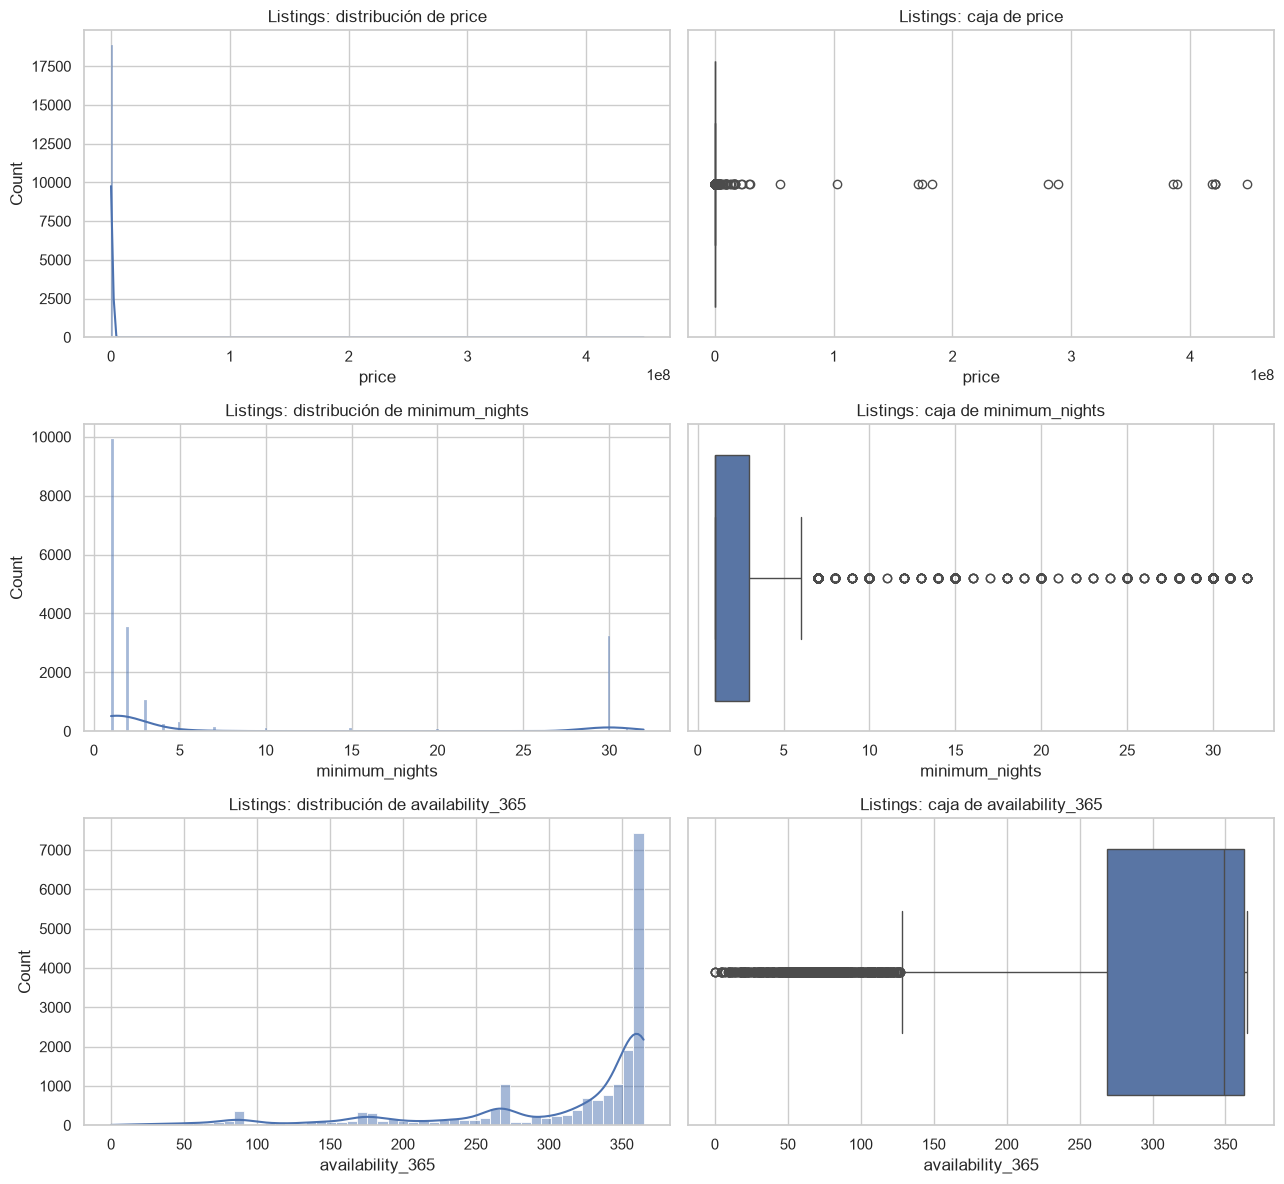

Reviews: no contiene las variables objetivo para estos gráficos.


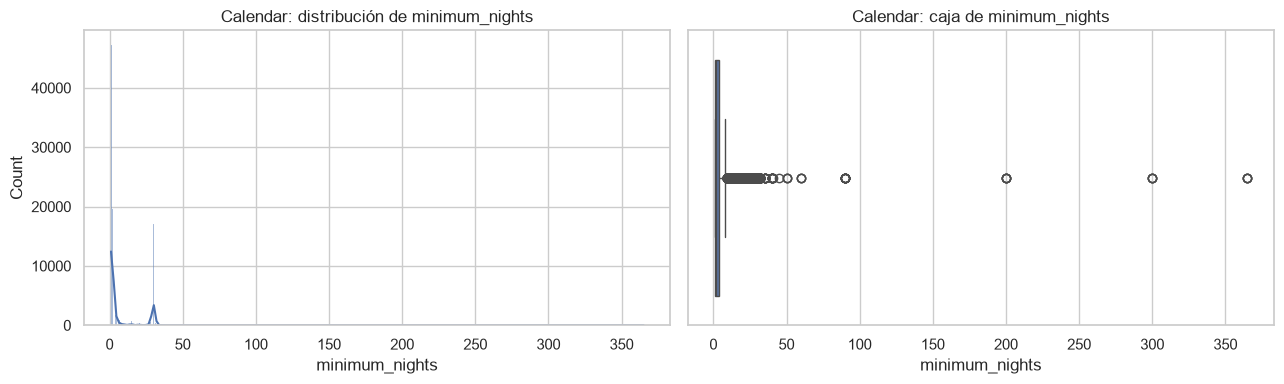

n  outliers_iqr        q1          q3  \
collection variable                                                        
Listings   price               18992          1410  110000.0  230346.375   
           minimum_nights      19183          4053       1.0       3.000   
           availability_365    19187          1129     269.0     363.000   
Calendar   minimum_nights    7003255       1451607       1.0       4.000   

                                iqr_low     iqr_high       min    median  \
collection variable                                                        
Listings   price            -70519.5625  410865.9375  19181.11  161460.0   
           minimum_nights       -2.0000       6.0000      1.00       1.0   
           availability_365    128.0000     504.0000      0.00     349.0   
Calendar   minimum_nights       -3.5000       8.5000      1.00       2.0   

                                     max  
collection variable                       
Listings   price             448176567.0  
           minimum_nights           32.0  
           availability_365        365.0  
Calendar   minimum_nights          365.0

In [4]:
variables = ["price", "minimum_nights", "availability_365"]
outlier_summary = {}
for name, frame in data.items():
    present = [c for c in variables if c in frame.columns]
    if not present:
        print(f"{name}: no contiene las variables objetivo para estos gráficos.")
        continue
    fig, axes = plt.subplots(len(present), 2, figsize=(13, 4 * len(present)))
    if len(present) == 1:
        axes = [axes]
    for column, (hist_ax, box_ax) in zip(present, axes):
        values = pd.to_numeric(frame[column], errors="coerce").dropna()
        plot_values = values.sample(n=100_000, random_state=42) if len(values) > 100_000 else values
        sns.histplot(plot_values, kde=len(plot_values) > 1, ax=hist_ax)
        hist_ax.set_title(f"{name}: distribución de {column}")
        sns.boxplot(x=plot_values, ax=box_ax)
        box_ax.set_title(f"{name}: caja de {column}")
        if len(values):
            q1, q3 = values.quantile([0.25, 0.75])
            iqr = q3 - q1
            count = int(((values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)).sum())
            outlier_summary[(name, column)] = {
                "n": len(values), "outliers_iqr": count,
                "q1": q1, "q3": q3,
                "iqr_low": q1 - 1.5 * iqr, "iqr_high": q3 + 1.5 * iqr,
                "min": values.min(), "median": values.median(), "max": values.max()
            }
    plt.tight_layout()
    plt.show()
pd.DataFrame.from_dict(outlier_summary, orient="index").rename_axis(
    ["collection", "variable"]
)

## 3. Campos anidados, fechas y relaciones

El bloque identifica columnas con estructura compleja, revisa relaciones numéricas cuando hay datos suficientes y resume el calendario por mes si contiene `date`. La correlación describe asociación lineal y no causalidad.

Listings: columnas con objetos/listas anidadas: ['amenities']


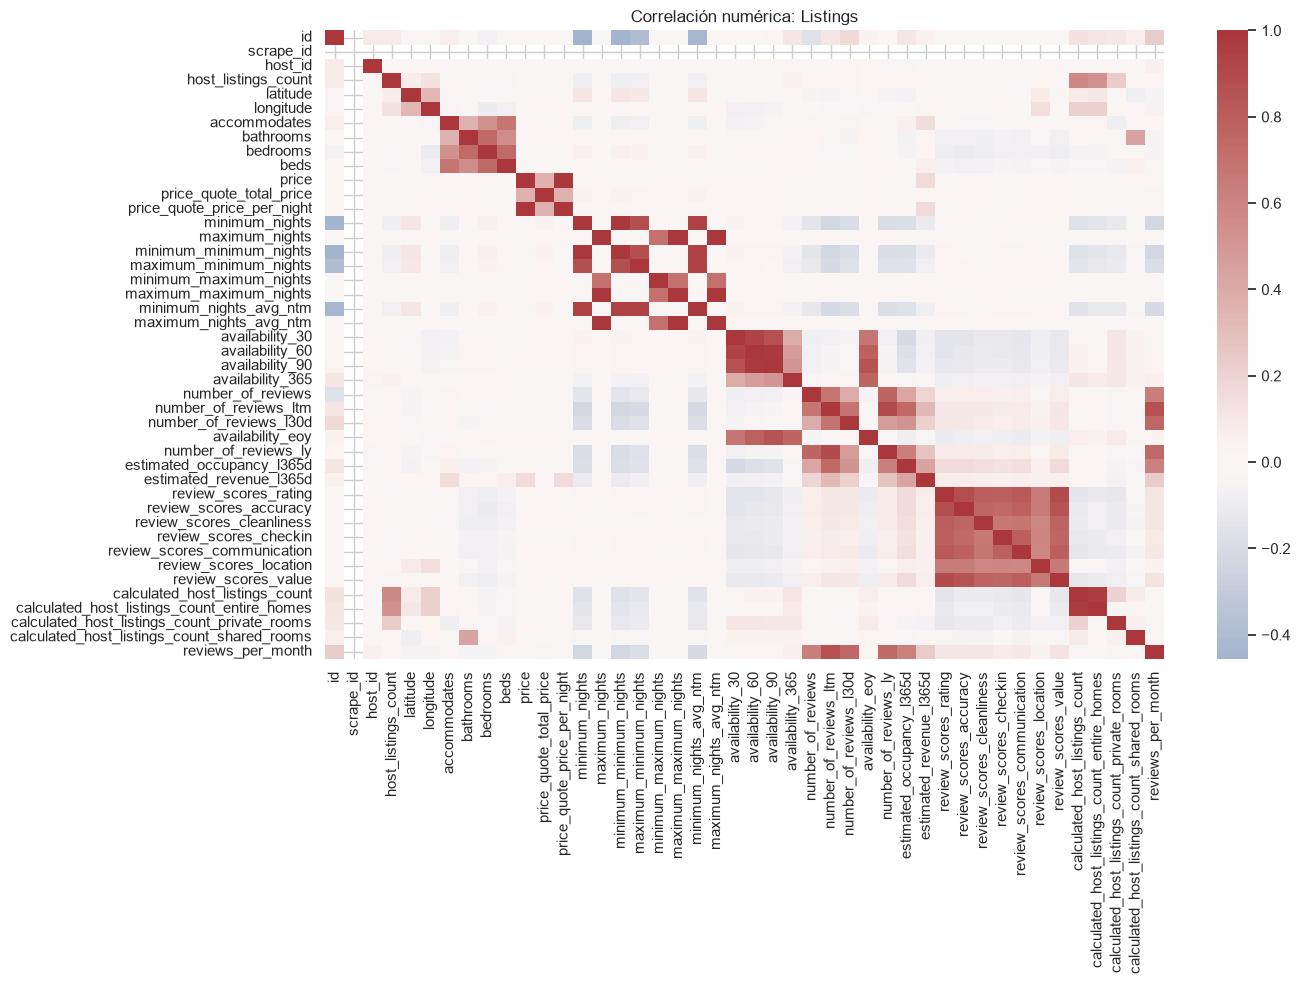

Pares con mayor correlación absoluta:


correlation
maximum_nights              maximum_maximum_nights          1.000000
minimum_minimum_nights      minimum_nights                  1.000000
price                       price_quote_price_per_night     1.000000
maximum_maximum_nights      maximum_nights                  1.000000
minimum_nights              minimum_minimum_nights          1.000000
price_quote_price_per_night price                           1.000000
maximum_nights_avg_ntm      maximum_nights                  0.999999
                            maximum_maximum_nights          0.999999
maximum_nights              maximum_nights_avg_ntm          0.999999
maximum_maximum_nights      maximum_nights_avg_ntm          0.999999

Reviews: columnas con objetos/listas anidadas: ninguna detectada


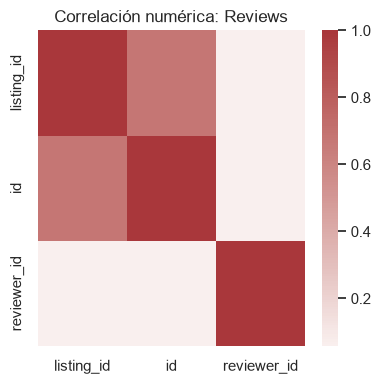

Pares con mayor correlación absoluta:


,,correlation
listing_id,id,0.677411
id,listing_id,0.677411
reviewer_id,id,0.063038
id,reviewer_id,0.063038
listing_id,reviewer_id,0.056776
reviewer_id,listing_id,0.056776
listing_id,listing_id,NaN
id,id,NaN
reviewer_id,reviewer_id,NaN


Calendar: columnas con objetos/listas anidadas: ninguna detectada


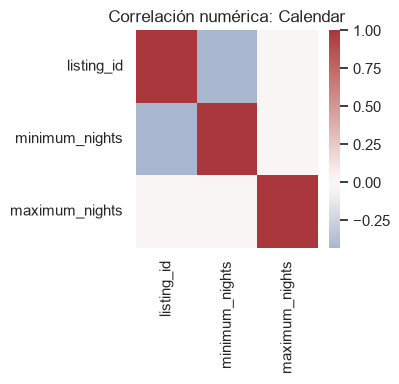

Pares con mayor correlación absoluta:


,,correlation
listing_id,minimum_nights,-0.429912
minimum_nights,listing_id,-0.429912
listing_id,maximum_nights,-0.022830
maximum_nights,listing_id,-0.022830
minimum_nights,maximum_nights,-0.007739
maximum_nights,minimum_nights,-0.007739
listing_id,listing_id,NaN
minimum_nights,minimum_nights,NaN
maximum_nights,maximum_nights,NaN


,records
month,
2026-06,174141
2026-07,594797
2026-08,594797
2026-09,575610
2026-10,594797
2026-11,575610
2026-12,594797
2027-01,594797
2027-02,537236


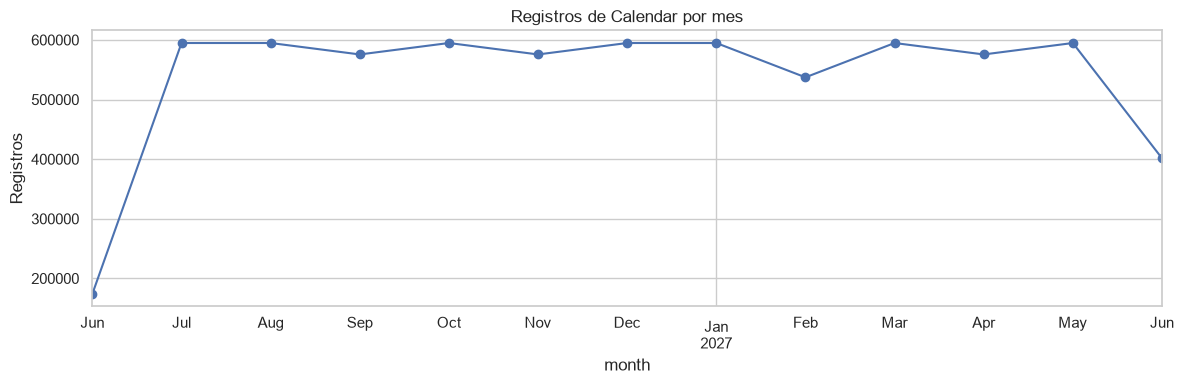

In [5]:
for name, frame in data.items():
    nested = [c for c in frame.columns if frame[c].map(
        lambda value: isinstance(value, (dict, list, tuple))
    ).any()]
    print(f"{name}: columnas con objetos/listas anidadas: {nested or 'ninguna detectada'}")
    numeric = frame.select_dtypes(include="number")
    if numeric.shape[1] >= 2:
        corr = numeric.corr(min_periods=2)
        plt.figure(figsize=(min(14, 1 + corr.shape[1]), min(10, 1 + corr.shape[1])))
        sns.heatmap(corr, cmap="vlag", center=0, annot=False)
        plt.title(f"Correlación numérica: {name}")
        plt.tight_layout()
        plt.show()
        pairs = corr.where(~pd.DataFrame(
            [[i == j for j in corr.columns] for i in corr.index],
            index=corr.index, columns=corr.columns
        )).stack().sort_values(key=abs, ascending=False)
        print("Pares con mayor correlación absoluta:")
        display(pairs.head(10).to_frame("correlation"))

calendar = data.get("Calendar", pd.DataFrame())
if "date" in calendar.columns:
    calendar_dates = pd.to_datetime(calendar["date"], errors="coerce", format="mixed")
    monthly = calendar.assign(month=calendar_dates.dt.to_period("M")).dropna(subset=["month"])
    monthly_counts = monthly.groupby("month").size().rename("records")
    display(monthly_counts.to_frame())
    monthly_counts.plot(figsize=(12, 4), marker="o", title="Registros de Calendar por mes")
    plt.ylabel("Registros")
    plt.tight_layout()
    plt.show()
else:
    print("Calendar no contiene una columna date; no es posible agrupar por mes.")

## 4. Hallazgos y decisiones para la transformación

El resumen siguiente se calcula al ejecutar el Notebook. Debe revisarse e interpretarse antes de incorporarlo al informe final; la detección estadística no reemplaza la validación del dominio.

In [6]:
for name, metrics in quality.items():
    null_columns = metrics["nulls"].index.tolist()
    null_total = int(metrics["nulls"].sum())
    display(Markdown(
        f"### {name}\n"
        f"- Registros y columnas observados: **{metrics['rows']:,} x {metrics['columns']:,}**.\n"
        f"- Duplicados exactos: **{metrics['duplicates']:,}**. Revisar y eliminar "
        f"duplicados exactos en la transformación, si se confirma que no representan eventos repetidos.\n"
        f"- Nulos registrados: **{null_total:,}** en {len(null_columns)} columnas. "
        f"Conservar nulos parciales evita descartar filas completas; decidir imputaciones según el uso analítico.\n"
        f"- Columnas con nulos: {', '.join(null_columns[:15]) if null_columns else 'ninguna'}."
    ))

display(Markdown(
    "### Decisiones propuestas para ETL\n"
    "1. Eliminar filas vacías y duplicados exactos, y conservar nulos parciales para "
    "no sesgar el tamaño de las colecciones.\n"
    "2. Normalizar `price` quitando símbolos monetarios/separadores y convertirlo a numérico; "
    "validar los valores que no puedan convertirse.\n"
    "3. Estandarizar fechas y derivar año, mes, día y trimestre desde `date`.\n"
    "4. Aplanar documentos anidados y mantener listas serializadas para conservar el detalle; "
    "derivar el conteo de amenities cuando aplique.\n"
    "5. Revisar valores atípicos con estadísticas y contexto de negocio antes de excluirlos; "
    "la implementación no elimina outliers automáticamente."
))

### Listings
- Registros y columnas observados: **19,187 x 91**.
- Duplicados exactos: **0**. Revisar y eliminar duplicados exactos en la transformación, si se confirma que no representan eventos repetidos.
- Nulos registrados: **295,610** en 46 columnas. Conservar nulos parciales evita descartar filas completas; decidir imputaciones según el uso analítico.
- Columnas con nulos: neighborhood_overview, host_acceptance_rate, host_since, host_response_time, host_thumbnail_url, host_response_rate, instant_bookable, neighbourhood_group_cleansed, neighbourhood, host_total_listings_count, host_neighbourhood, calendar_updated, host_about, host_location, review_scores_value.

### Reviews
- Registros y columnas observados: **527,731 x 7**.
- Duplicados exactos: **0**. Revisar y eliminar duplicados exactos en la transformación, si se confirma que no representan eventos repetidos.
- Nulos registrados: **0** en 0 columnas. Conservar nulos parciales evita descartar filas completas; decidir imputaciones según el uso analítico.
- Columnas con nulos: ninguna.

### Calendar
- Registros y columnas observados: **7,003,255 x 6**.
- Duplicados exactos: **0**. Revisar y eliminar duplicados exactos en la transformación, si se confirma que no representan eventos repetidos.
- Nulos registrados: **0** en 0 columnas. Conservar nulos parciales evita descartar filas completas; decidir imputaciones según el uso analítico.
- Columnas con nulos: ninguna.

### Decisiones propuestas para ETL
1. Eliminar filas vacías y duplicados exactos, y conservar nulos parciales para no sesgar el tamaño de las colecciones.
2. Normalizar `price` quitando símbolos monetarios/separadores y convertirlo a numérico; validar los valores que no puedan convertirse.
3. Estandarizar fechas y derivar año, mes, día y trimestre desde `date`.
4. Aplanar documentos anidados y mantener listas serializadas para conservar el detalle; derivar el conteo de amenities cuando aplique.
5. Revisar valores atípicos con estadísticas y contexto de negocio antes de excluirlos; la implementación no elimina outliers automáticamente.